# Motivation over the years

**Descriptive question:** Has the percentage of students selecting “It is the most exciting” changed across survey years?

**Prediction question:** Can students' motivation choices predict the year they answered?

We keep this close to the original analysis: read the data → clean it → plot → split into training/test sets → train two simple classifiers → compare with a baseline.

**Assignment methods:** we implement multi-label encoding and standardization ourselves, then implement **nearest-centroid** and **K-nearest neighbours (KNN)** classifiers using NumPy. Nearest-centroid compares average yearly profiles; KNN compares individual training students. Library functions are used only for file handling, plotting, and splitting the data—not for preprocessing algorithms or the classifier.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

### Read and combine the data

The shared function in `load_student_data.py` reads all four formats, removes password columns, and combines the tables. Each call returns a fresh table.

In [2]:
from load_student_data import load_student_data

# Read and combine the four survey files using the shared Python function.
students_df = load_student_data()
print("Total responses:", len(students_df))

Total responses: 223


### Extract the survey year
The file named 2023 contains answers from **2020, 2021, and 2023**. We extract the year from each timestamp instead of using the filename.

The older file uses `DD/MM/YYYY`, while the newer files start with `YYYY`. Only the year is needed for this analysis.

In [3]:
# The older file uses DD/MM/YYYY; the newer files start with YYYY.
# We only need the year, so there is no need to convert time zones.
students_df["year"] = [
    int(timestamp.split(" ")[0].split("/")[-1]) if source == 2023
    else int(timestamp[:4])
    for timestamp, source in zip(students_df["timestamp"], students_df["source_file"])
]

print(students_df["year"].value_counts().sort_index())

year
2020    50
2021     7
2023    33
2024    38
2025    50
2026    45
Name: count, dtype: int64


### Clean the reasons
Remove missing or blank answers rather than treating them as “not excited.” Convert text to lowercase and remove surrounding spaces.

Students could select several options. We check whether the exact option **“It is the most exciting”** appears anywhere in the answer. Other choices can appear alongside it. This measures selection of an option, not a person's mood.

In [4]:
valid = students_df["course_reason"].notna() & students_df["course_reason"].astype(str).str.strip().ne("")
print("Excluded missing or blank answers:", (~valid).sum())
students_df = students_df.loc[valid].copy()
students_df["reason_clean"] = students_df["course_reason"].str.lower().str.strip()
students_df["exciting"] = [int("it is the most exciting" in answer)
                           for answer in students_df["reason_clean"]]

Excluded missing or blank answers: 0


### How did excitement change?
Compare percentages rather than counts because the cohorts have different sizes. These are different groups of students, not the same students followed over time.

,students,selected_exciting,exciting_percent
year,,,
2020,50,22,44.0
2021,7,5,71.4
2023,33,12,36.4
2024,38,18,47.4
2025,50,31,62.0
2026,45,25,55.6


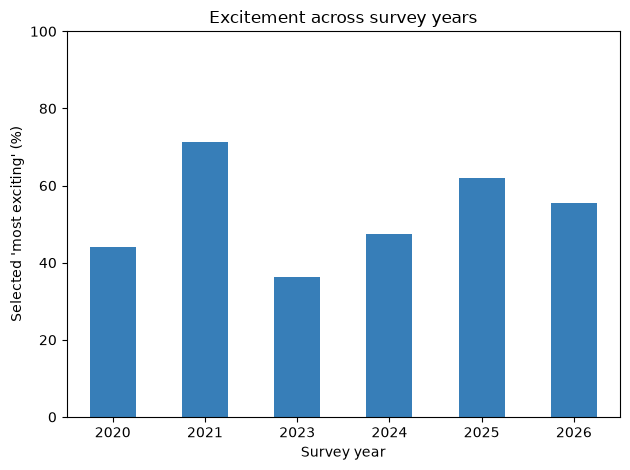

In [5]:
year_summary = students_df.groupby("year").agg(
    students=("exciting", "size"), selected_exciting=("exciting", "sum")
)
year_summary["exciting_percent"] = 100 * year_summary["selected_exciting"] / year_summary["students"]
display(year_summary.round(1))

year_summary["exciting_percent"].plot.bar(color="#377eb8", rot=0)
plt.ylabel("Selected 'most exciting' (%)")
plt.xlabel("Survey year")
plt.title("Excitement across survey years")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### Preprocessing 1: encode motivation choices as numbers
Create five columns. **1 means selected, 0 means not selected.** A student can have several 1s.

Treat “business skills” and “commercially useful skills” as the same category so the model cannot simply recognize that wording change. Do not split on commas: the “not sure” option itself contains a comma. Custom text is not used as an extra feature; answers containing only custom text will have five zeros.

The model receives **only these five reasons**. It does not receive dates, year, weather, programme, height, or shoe size as inputs.

In [6]:
reason_options = {
    "exciting": ["it is the most exciting"],
    "career_skills": ["it'll give me business skills", "it'll give me commercially useful skills"],
    "mandatory": ["this was mandatory for me"],
    "unsure": ["i'm not sure, let's see how it works out"],
    "less_attractive_alternatives": ["the other courses were even less attractive"],
}

# Implement multi-label encoding directly rather than using an encoder library.
for column, phrases in reason_options.items():
    students_df[column] = [
        int(any(phrase in answer for phrase in phrases))
        for answer in students_df["reason_clean"]
    ]

X = students_df[list(reason_options)].to_numpy(dtype=float)
y = students_df["year"].to_numpy()
display(students_df[list(reason_options)].head())
print("Answers with no recognized option:", (X.sum(axis=1) == 0).sum())

,exciting,career_skills,mandatory,unsure,less_attractive_alternatives
0,0,1,0,0,0
1,1,1,1,0,0
2,0,0,1,0,0
3,1,1,0,0,0
4,0,1,0,0,0


Answers with no recognized option: 11


### Split before learning from the data
Use 80% of students for training and 20% for testing. `stratify=y` keeps every year represented in both sets. The fixed random seed makes the results reproducible.

This tests prediction for another student from these **known cohorts**, not a future unseen year. Students from the same survey date can appear in both sets, so this is a limited classroom experiment rather than evidence of performance on new cohorts.

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training students:", len(y_train))
print("Test students:", len(y_test))

Training students: 178
Test students: 45


### Preprocessing 2: standardize the inputs
Implement **z = (value − mean) / standard deviation**. Calculate the mean and standard deviation using only training students, then apply those same numbers to test students.

Although the original columns are all 0/1, their frequencies differ. Standardization gives each column unit training variance; this makes uncommon options more influential in the distance calculation. This is a modelling choice. If a column is constant, use a divisor of 1 to avoid division by zero.

In [8]:
training_mean = X_train.mean(axis=0)
training_std = X_train.std(axis=0)
training_std[training_std == 0] = 1

X_train_scaled = (X_train - training_mean) / training_std
X_test_scaled = (X_test - training_mean) / training_std

### Train a nearest-centroid classifier
A **centroid** is an average profile. For each year, calculate the average of its training students' encoded reasons.

For a test student, calculate the squared Euclidean distance to each year's profile and choose the closest one. This is supervised classification because the training years tell us which students belong to each profile. We implement both training and prediction below; there is no library classifier.

In [9]:
# Training: learn one average motivation profile for each year.
years = np.unique(y_train)
centroids = np.array([
    X_train_scaled[y_train == year].mean(axis=0)
    for year in years
])

# Prediction: choose the year with the closest average profile.
predictions = []
for student in X_test_scaled:
    distances = np.sum((centroids - student) ** 2, axis=1)
    closest_year = years[np.argmin(distances)]
    predictions.append(closest_year)
predictions = np.array(predictions)

# Exact distance ties select the first (earliest) year in the sorted list.
print("First five predicted years:", predictions[:5])
print("First five actual years:   ", y_test[:5])

First five predicted years: [2020 2026 2026 2026 2026]
First five actual years:    [2025 2024 2025 2025 2024]


### Add a second model: K-nearest neighbours (KNN)
Instead of averaging an entire year, KNN finds the **five training students with the closest motivation choices**. It predicts the year that appears most often among those neighbours.

KNN keeps the labelled training examples rather than fitting coefficients. We implement the distance calculation and voting ourselves. Set **K = 5** as a simple fixed choice, without searching for the best K using test results.

Many students have identical answer profiles. Equal distances are resolved by training-row order; equal vote counts are resolved by choosing the earliest year. These rules make results reproducible, but ties can affect this small dataset.

In [10]:
k = 5
knn_predictions = []

for student in X_test_scaled:
    # Measure distance to every training student using the same scaled inputs.
    distances = np.sum((X_train_scaled - student) ** 2, axis=1)
    nearest_indices = np.argsort(distances, kind="stable")[:k]
    neighbour_years = y_train[nearest_indices]

    # Count the neighbours' years and choose the most frequent one.
    possible_years, votes = np.unique(neighbour_years, return_counts=True)
    predicted_year = possible_years[np.argmax(votes)]
    knn_predictions.append(predicted_year)

knn_predictions = np.array(knn_predictions)
print("First five KNN predictions:", knn_predictions[:5])
print("First five actual years:  ", y_test[:5])

First five KNN predictions: [2020 2026 2023 2023 2023]
First five actual years:   [2025 2024 2025 2025 2024]


### Compare both models with a simple baseline
The baseline always predicts the most frequent year **in the training set**. Both models use the same training/test students and the same standardized inputs. Accuracy is the proportion of correct predictions; we also report the number correct and show each model's confusion table.

KNN was added after inspecting the first model's result, so this comparison is **exploratory**. We do not tune K on this test set. A fresh test set would be needed to confirm a claimed improvement.

,Method,Correct predictions,Test students,Test accuracy (%)
0,Most common year baseline,10,45,22.2
1,Nearest-centroid,12,45,26.7
2,KNN (K=5),10,45,22.2


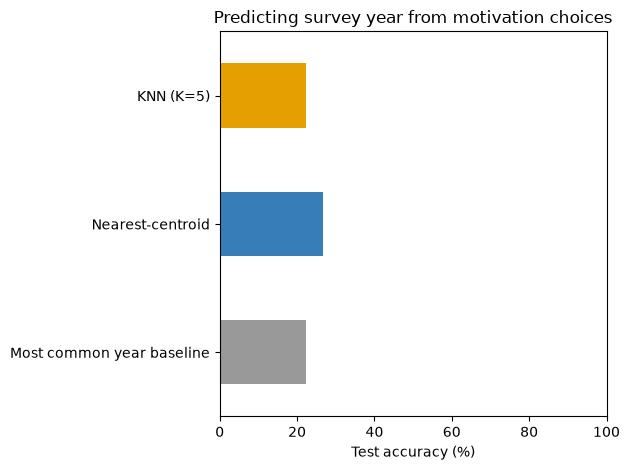

Nearest-centroid


Predicted year,2020,2021,2023,2024,2025,2026
Actual year,,,,,,
2020,1,2,1,2,0,4
2021,0,1,0,0,0,0
2023,2,1,1,0,0,3
2024,0,1,0,0,0,7
2025,1,1,0,1,0,7
2026,0,0,0,0,0,9


KNN (K=5)


Predicted year,2020,2021,2023,2024,2025,2026
Actual year,,,,,,
2020,3,0,1,3,0,3
2021,0,1,0,0,0,0
2023,2,1,3,1,0,0
2024,0,0,3,1,0,4
2025,2,1,2,0,0,5
2026,0,0,7,0,0,2


In [11]:
most_common_year = pd.Series(y_train).value_counts().idxmax()
baseline_predictions = np.full(len(y_test), most_common_year)

# Compare all methods on exactly the same test students.
all_predictions = {
    "Most common year baseline": baseline_predictions,
    "Nearest-centroid": predictions,
    "KNN (K=5)": knn_predictions,
}
comparison_rows = []
for name, predicted in all_predictions.items():
    correct = np.sum(predicted == y_test)
    comparison_rows.append({"Method": name, "Correct predictions": correct,
                            "Test students": len(y_test),
                            "Test accuracy (%)": 100 * correct / len(y_test)})
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(1))

comparison.plot.barh(x="Method", y="Test accuracy (%)", legend=False,
                    color=["#999999", "#377eb8", "#e69f00"])
plt.xlabel("Test accuracy (%)")
plt.ylabel("")
plt.xlim(0, 100)
plt.title("Predicting survey year from motivation choices")
plt.tight_layout()
plt.show()

# Rows are actual years; columns are predicted years.
for name in ["Nearest-centroid", "KNN (K=5)"]:
    print(name)
    confusion = pd.crosstab(
        pd.Series(y_test, name="Actual year"),
        pd.Series(all_predictions[name], name="Predicted year")
    ).reindex(index=years, columns=years, fill_value=0)
    display(confusion)

### Answers and limitations

In [12]:
highest = year_summary["exciting_percent"].idxmax()
lowest = year_summary["exciting_percent"].idxmin()
centroid_correct = np.sum(predictions == y_test)
knn_correct = np.sum(knn_predictions == y_test)
baseline_correct = np.sum(baseline_predictions == y_test)
if knn_correct > centroid_correct:
    comparison_text = "KNN made more correct predictions than nearest-centroid on this split."
elif knn_correct < centroid_correct:
    comparison_text = "Nearest-centroid made more correct predictions than KNN on this split."
else:
    comparison_text = "Both classifiers made the same number of correct predictions on this split."

display(Markdown(f"""**Excitement across years:** The observed percentage ranged from
**{year_summary.loc[lowest, 'exciting_percent']:.1f}% in {lowest}** to
**{year_summary.loc[highest, 'exciting_percent']:.1f}% in {highest}**.
This describes differences between cohorts, not a change in the same individuals.

**Predicting the year (same {len(y_test)} test students):**
- Baseline: **{baseline_correct}/{len(y_test)} correct ({baseline_correct / len(y_test):.1%})**.
- Nearest-centroid: **{centroid_correct}/{len(y_test)} correct ({centroid_correct / len(y_test):.1%})**.
- KNN: **{knn_correct}/{len(y_test)} correct ({knn_correct / len(y_test):.1%})**.

{comparison_text} Each additional correct student changes accuracy by about
**{100 / len(y_test):.1f} percentage points**. This small, previously inspected test set
does not establish a reliable advantage for either model.
"""))

**Excitement across years:** The observed percentage ranged from
**36.4% in 2023** to
**71.4% in 2021**.
This describes differences between cohorts, not a change in the same individuals.

**Predicting the year (same 45 test students):**
- Baseline: **10/45 correct (22.2%)**.
- Nearest-centroid: **12/45 correct (26.7%)**.
- KNN: **10/45 correct (22.2%)**.

Nearest-centroid made more correct predictions than KNN on this split. Each additional correct student changes accuracy by about
**2.2 percentage points**. This small, previously inspected test set
does not establish a reliable advantage for either model.


- Some years have very few students; 2021 has only seven. Results for small groups are especially uncertain.
- The same five-option profile can occur in several years. The model cannot distinguish students with identical inputs.
- Programme composition, survey wording, and course requirements may differ across cohorts. These may explain motivation differences.
- Students answering on the same day may be similar. Our student-level split does not test generalization to independent survey days or future years.
- These simple classifiers may perform poorly. Reporting weak performance is a valid answer; it means these inputs and this method were not sufficient for accurate prediction in this test.

**Requirements covered:** manually implemented categorical encoding, training-only standardization, and two supervised classifiers: nearest-centroid and KNN. Text cleaning and missing-answer handling are also included. No weather data are needed for this notebook.